In [1]:
import warnings
warnings.filterwarnings("ignore")

In [2]:
import nbimporter
from bike_sharing_data import get_bike_sharing

X_train, X_test, y_train, y_test = get_bike_sharing()

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (13903, 12)
Testing data: (3476, 12)


In [4]:
from sklearn.linear_model import (
    ElasticNet,
    MultiTaskElasticNet,
    ElasticNetCV
)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

elastic_model = make_pipeline(
    StandardScaler(),
    ElasticNet(
        alpha=1.0,
        l1_ratio=0.5,
        max_iter=10000,
        random_state=42
    )
)

elastic_model.fit(X_train, y_train)

,steps,"[('standardscaler', ...), ('elasticnet', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,alpha,1.0
,l1_ratio,0.5
,fit_intercept,True
,precompute,False


In [5]:
y_train_pred_en = elastic_model.predict(X_train)
y_test_pred_en = elastic_model.predict(X_test)

In [6]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

train_r2_en = r2_score(y_train, y_train_pred_en)
test_r2_en = r2_score(y_test, y_test_pred_en)

mae_en = mean_absolute_error(y_test, y_test_pred_en)
mse_en = mean_squared_error(y_test, y_test_pred_en)
rmse_en = np.sqrt(mse_en)

print("ElasticNet Regression")
print("---------------------")
print("Train R2:", train_r2_en)
print("Test R2 :", test_r2_en)
print("MAE     :", mae_en)
print("MSE     :", mse_en)
print("RMSE    :", rmse_en)

ElasticNet Regression
---------------------
Train R2: 0.3653065936828366
Test R2 : 0.3666398104457319
MAE     : 106.10036665927142
MSE     : 20055.6109263721
RMSE    : 141.6178340689198


In [7]:
elastic_cv_model = make_pipeline(
    StandardScaler(),
    ElasticNetCV(
        l1_ratio=[0.1, 0.5, 0.7, 0.9, 1.0],
        alphas=100,
        cv=5,
        max_iter=10000,
        random_state=42
    )
)

elastic_cv_model.fit(X_train, y_train)

,steps,"[('standardscaler', ...), ('elasticnetcv', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,l1_ratio,"[0.1, 0.5, ...]"
,eps,0.001
,n_alphas,'deprecated'
,alphas,100


In [8]:
y_train_pred_cv = elastic_cv_model.predict(X_train)
y_test_pred_cv = elastic_cv_model.predict(X_test)

In [9]:
train_r2_cv = r2_score(y_train, y_train_pred_cv)
test_r2_cv = r2_score(y_test, y_test_pred_cv)

mae_cv = mean_absolute_error(y_test, y_test_pred_cv)
mse_cv = mean_squared_error(y_test, y_test_pred_cv)
rmse_cv = np.sqrt(mse_cv)

print("ElasticNetCV")
print("------------")
print("Train R2:", train_r2_cv)
print("Test R2 :", test_r2_cv)
print("MAE     :", mae_cv)
print("MSE     :", mse_cv)
print("RMSE    :", rmse_cv)

# Best hyperparameters
enet_cv = elastic_cv_model.named_steps['elasticnetcv']

print("Best Alpha:", enet_cv.alpha_)
print("Best L1 Ratio:", enet_cv.l1_ratio_)

ElasticNetCV
------------
Train R2: 0.38880575171135845
Test R2 : 0.38800016985165975
MAE     : 104.7608995006446
MSE     : 19379.226359488843
RMSE    : 139.20928977438555
Best Alpha: 0.14771664472194695
Best L1 Ratio: 1.0


In [12]:
from bike_sharing_data import bike_sharing_dataset
from sklearn.model_selection import train_test_split

X, y, _ = bike_sharing_dataset()

df = X.join(y)

print(df.columns)

Index(['dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday',
       'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'cnt'],
      dtype='object')


In [13]:
# Select features
X_multi = df.drop(columns=['dteday', 'temp', 'cnt'])

# Select multiple targets
y_multi = df[
    ['temp', 'cnt']
]

In [14]:
# Split data
X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
    X_multi,
    y_multi,
    test_size=0.2,
    random_state=42
)

# Create model
multi_model = make_pipeline(
    StandardScaler(),
    MultiTaskElasticNet(
        alpha=1.0,
        l1_ratio=0.5,
        max_iter=10000
    )
)

# Train model
multi_model.fit(X_train_m, y_train_m)

,steps,"[('standardscaler', ...), ('multitaskelasticnet', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,alpha,1.0
,l1_ratio,0.5
,fit_intercept,True
,copy_X,True


In [15]:
y_train_pred_multi = multi_model.predict(X_train_m)
y_test_pred_multi = multi_model.predict(X_test_m)

In [16]:
train_r2_multi = r2_score(y_train_m, y_train_pred_multi)
test_r2_multi = r2_score(y_test_m, y_test_pred_multi)

mae_multi = mean_absolute_error(y_test_m, y_test_pred_multi)
mse_multi = mean_squared_error(y_test_m, y_test_pred_multi)
rmse_multi = np.sqrt(mse_multi)

print("MultiTaskElasticNet Regression")
print("------------------------------")
print("Train R2:", train_r2_multi)
print("Test R2 :", test_r2_multi)
print("MAE     :", mae_multi)
print("MSE     :", mse_multi)
print("RMSE    :", rmse_multi)

MultiTaskElasticNet Regression
------------------------------
Train R2: 0.6115105320134662
Test R2 : 0.6124648712315928
MAE     : 53.438267155708715
MSE     : 10145.08150642592
RMSE    : 100.72279536642101


In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

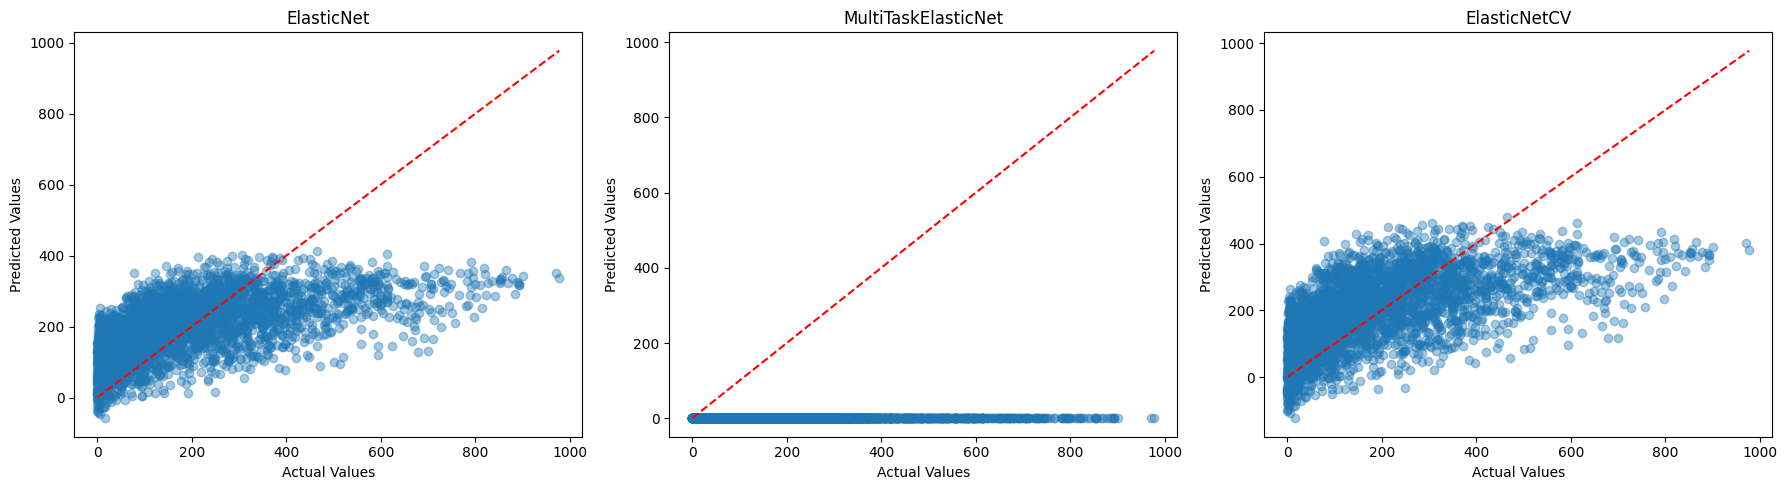

In [18]:
import pandas as pd

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

models = [
    ("ElasticNet", y_test_pred_en),
    ("MultiTaskElasticNet", y_test_pred_multi[:, 0]),
    ("ElasticNetCV", y_test_pred_cv)
]

# This plot assumes the multi-task model predicts
# the same first target being evaluated separately.
actual = y_test if isinstance(y_test, pd.Series) else y_test.iloc[:, 0]

for ax, (name, pred) in zip(axes, models):

    ax.scatter(actual, pred, alpha=0.4)

    ax.plot(
        [actual.min(), actual.max()],
        [actual.min(), actual.max()],
        'r--'
    )

    ax.set_xlabel("Actual Values")
    ax.set_ylabel("Predicted Values")
    ax.set_title(name)

plt.tight_layout()
plt.show()

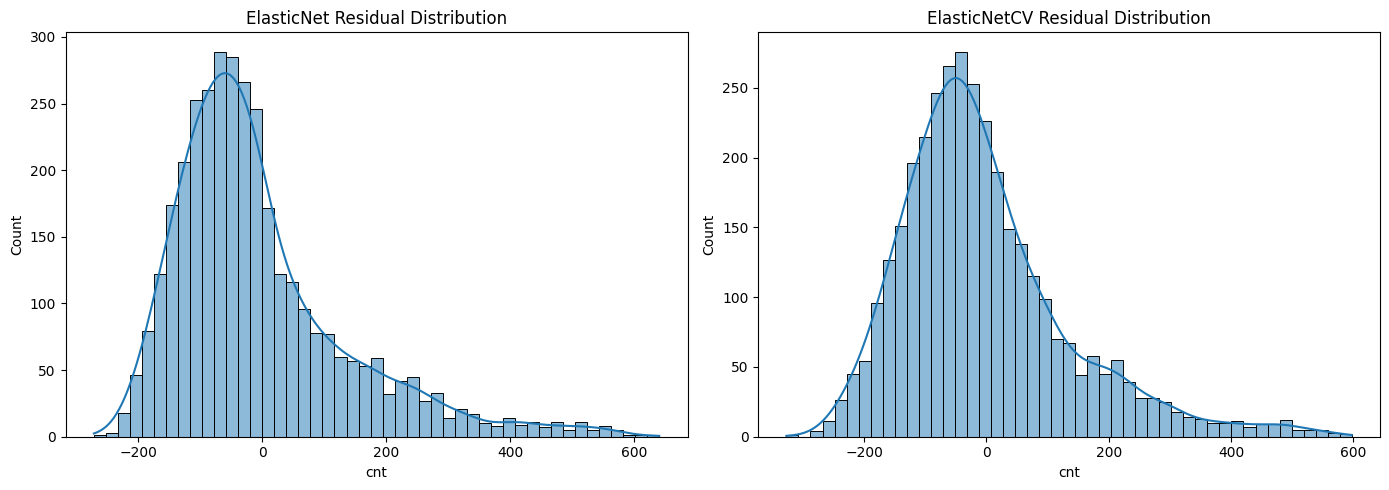

In [19]:
residuals_en = y_test - y_test_pred_en
residuals_cv = y_test - y_test_pred_cv

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(residuals_en, kde=True, ax=axes[0])
axes[0].set_title("ElasticNet Residual Distribution")

sns.histplot(residuals_cv, kde=True, ax=axes[1])
axes[1].set_title("ElasticNetCV Residual Distribution")

plt.tight_layout()
plt.show()